# YaLlegó Delivery — Misión 7 | P1 y P5
**Responsable:** Guillermo Gabriel Urquidi Salinas · Introducción a la Ciencia de Datos II · UPB · Gestión II-2026  
**Período:** 2025.

Objetivo: responder P1 y P5 mediante SQL en DuckDB, visualizaciones y control de calidad. Se conserva la decisión de José de excluir 140 pedidos huérfanos: universo de 75.192 pedidos. Los resultados de referencia de las secciones 2.5 y 3.5 fueron recalculados de forma independiente con pandas y `plata.py`; la evidencia y los gráficos están al final. **El SQL no se ha ejecutado en esta revisión (DuckDB no está disponible en el entorno); ejecutar en Colab con la base definitiva y cotejar.** Las frases para gerencia y la reflexión crítica son borradores de apoyo, no interpretaciones personales ya aprobadas por el estudiante.

In [3]:
!pip install -q duckdb

import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns
import math
from pathlib import Path

## 1. Conexión y control de la base
Subir la base generada por `pipeline.py` (`yallego.duckdb`), o la base provisional `yallego_analisis.duckdb` para trabajar individualmente. Se prefiere la base definitiva si ambas existen. Conexión de solo lectura.

In [4]:
ruta_db = next((p for p in [Path("yallego.duckdb"), Path("yallego_analisis.duckdb")] if p.is_file()), None)
assert ruta_db is not None, "Sube la base DuckDB validada antes de continuar."
con = duckdb.connect(str(ruta_db), read_only=True)
print("Base utilizada:", ruta_db)
display(con.sql("SHOW TABLES").df())

Base utilizada: yallego_analisis.duckdb


,name
0,bronce_pedidos
1,plata_clima
2,plata_feriados
3,plata_pedidos
4,plata_restaurantes
5,plata_riders
6,plata_zonas
7,rechazos_pedidos


In [5]:
def comprobar_tabla(tabla, columnas):
    esquema = con.sql(f"DESCRIBE {tabla}").df()
    display(esquema)
    faltan = set(columnas) - set(esquema["column_name"])
    assert not faltan, f"Faltan columnas en {tabla}: {faltan}"

comprobar_tabla("plata_pedidos", ["pedido_id", "fecha_hora", "zona_entrega", "estado", "cod_rest", "rider_id", "tiempo_entrega_min", "calificacion"])
control = con.sql("""
SELECT COUNT(*) AS filas, COUNT(DISTINCT pedido_id) AS ids_unicos,
       COUNT(*) FILTER (WHERE pedido_id IS NULL) AS ids_nulos,
       MIN(fecha_hora) AS primera_fecha, MAX(fecha_hora) AS ultima_fecha,
       COUNT(*) FILTER (WHERE fecha_hora IS NULL) AS fechas_nulas,
       COUNT(DISTINCT zona_entrega) AS zonas
FROM plata_pedidos
""").df()
display(control)
display(con.sql("SELECT estado, COUNT(*) AS pedidos FROM plata_pedidos GROUP BY estado").df())
assert control.loc[0, "filas"] == control.loc[0, "ids_unicos"]
assert control.loc[0, "fechas_nulas"] == 0
assert control.loc[0, "zonas"] == 12
assert pd.Timestamp(control.loc[0, "primera_fecha"]).year == 2025
assert pd.Timestamp(control.loc[0, "ultima_fecha"]).year == 2025
assert set(con.sql("SELECT DISTINCT estado FROM plata_pedidos").df()["estado"]) <= {"entregado", "cancelado"}
# 75.332 corresponde al control ANTES de decidir qué hacer con huérfanos.
# No exigir ese total a la plata definitiva si el equipo excluyó registros justificados.
assert control.loc[0,"filas"] == 75192, "La base no coincide con la decisión actual de excluir 140 huérfanos; revisar con José."

,column_name,column_type,null,key,default,extra
0,pedido_id,VARCHAR,YES,None,None,None
1,fecha_hora,TIMESTAMP_NS,YES,None,None,None
2,cod_cliente,VARCHAR,YES,None,None,None
3,cod_rest,VARCHAR,YES,None,None,None
4,zona_entrega,VARCHAR,YES,None,None,None
5,rider_id,VARCHAR,YES,None,None,None
6,monto_bs,DOUBLE,YES,None,None,None
7,costo_envio_bs,DOUBLE,YES,None,None,None
8,propina_bs,DOUBLE,YES,None,None,None
9,tiempo_entrega_min,DOUBLE,YES,None,None,None


,filas,ids_unicos,ids_nulos,primera_fecha,ultima_fecha,fechas_nulas,zonas
0,75192,75192,0,2025-01-01 07:05:50,2025-12-31 23:37:23,0,12


,estado,pedidos
0,entregado,71590
1,cancelado,3602


## 2. P1 — ¿Dónde y cuándo se concentra la demanda? ¿Cuántos riders necesitamos en la hora pico?
### 2.1 Criterios
- Demanda = pedidos únicos de plata (entregados y cancelados). Se considera fecha y hora local de Bolivia, que el pipeline debe haber normalizado correctamente.
- Grano del heatmap: día de la semana × hora de inicio. Promedio por ocurrencia de esa franja durante 2025; incluye franjas sin pedidos. No confundir con el total acumulado.
- Ranking de zonas: pedidos y participación sobre toda la demanda analizada.
- Capacidad: estimación para la misma franja típica que ocupa el primer lugar del heatmap. Se usa el promedio de entregas por ocurrencia y el tiempo promedio válido de esas entregas. Se reporta además el máximo histórico como escenario de estrés.
- Utilización objetivo: 80% (supuesto propuesto, no dato observado). Se supone una entrega a la vez y se usa el tiempo pedido–entrega como aproximación al tiempo de ocupación. No equivale a tiempo real de trabajo ni permite fijar una plantilla exacta. No incorpora demanda cancelada que podría recuperarse.
- Los resultados dependen de las decisiones de limpieza y exclusión de huérfanos.

### 2.2 Heatmap: demanda promedio por día y hora

In [6]:
consulta_p1_heatmap = """
WITH calendario AS (
    SELECT
        CAST(fecha AS DATE) AS fecha,
        EXTRACT(ISODOW FROM fecha) AS dia
    FROM generate_series(
        DATE '2025-01-01',
        DATE '2025-12-31',
        INTERVAL 1 DAY
    ) AS t(fecha)
),
pedidos_hora AS (
    SELECT
        CAST(fecha_hora AS DATE) AS fecha,
        EXTRACT(HOUR FROM fecha_hora) AS hora,
        COUNT(*) AS pedidos
    FROM plata_pedidos
    GROUP BY fecha, hora
)
SELECT
    c.dia,
    h.hora,
    SUM(COALESCE(p.pedidos, 0)) AS pedidos,
    AVG(COALESCE(p.pedidos, 0))
        AS pedidos_promedio
FROM calendario c
CROSS JOIN generate_series(0, 23) AS h(hora)
LEFT JOIN pedidos_hora p
    ON c.fecha = p.fecha
    AND h.hora = p.hora
GROUP BY c.dia, h.hora
ORDER BY c.dia, h.hora
"""

In [7]:
demanda_horaria = con.sql(
    consulta_p1_heatmap
).df()

display(demanda_horaria)
assert len(demanda_horaria) == 168
assert demanda_horaria["pedidos"].sum() == control.loc[0,"filas"]

,dia,hora,pedidos,pedidos_promedio
0,1,0,0.0,0.000000
1,1,1,0.0,0.000000
2,1,2,0.0,0.000000
3,1,3,0.0,0.000000
4,1,4,0.0,0.000000
...,...,...,...,...
163,7,19,1145.0,22.019231
164,7,20,1335.0,25.673077
165,7,21,1036.0,19.923077
166,7,22,553.0,10.634615


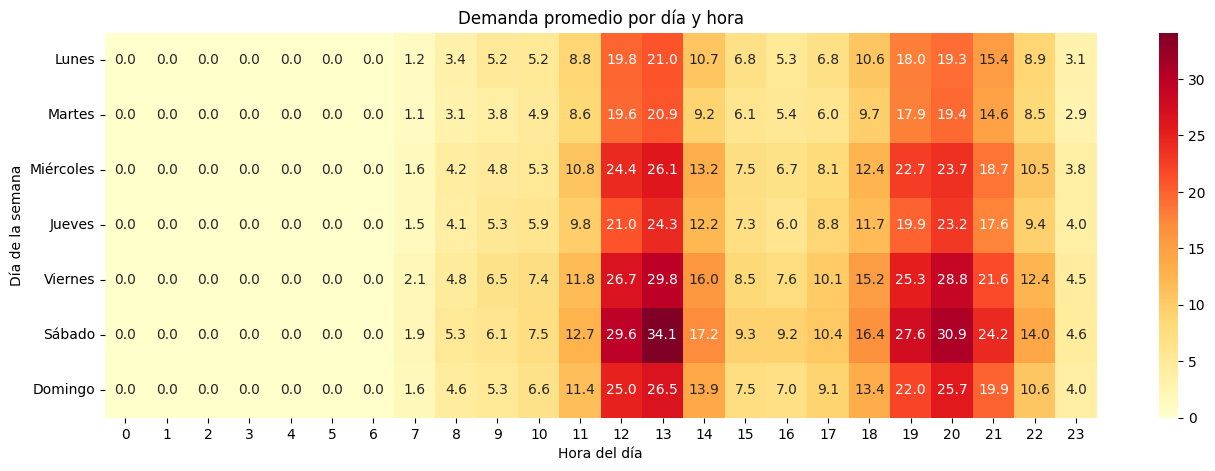

In [8]:
heatmap = demanda_horaria.pivot(
    index="dia",
    columns="hora",
    values="pedidos_promedio"
)

heatmap.index = [
    "Lunes", "Martes", "Miércoles",
    "Jueves", "Viernes", "Sábado", "Domingo"
]

plt.figure(figsize=(16, 5))

sns.heatmap(
    heatmap,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f"
)

plt.title("Demanda promedio por día y hora")
plt.xlabel("Hora del día")
plt.ylabel("Día de la semana")

plt.show()

In [9]:
dias = {1:"Lunes", 2:"Martes", 3:"Miércoles", 4:"Jueves", 5:"Viernes", 6:"Sábado", 7:"Domingo"}
hora_pico = demanda_horaria.sort_values(["pedidos_promedio", "dia", "hora"], ascending=[False, True, True]).head(1)
display(hora_pico)
dia_pico = int(hora_pico.iloc[0]["dia"])
hora = int(hora_pico.iloc[0]["hora"])
print(f"Franja típica pico: {dias[dia_pico]} {hora:02d}:00–{hora:02d}:59")

,dia,hora,pedidos,pedidos_promedio
133,6,13,1773.0,34.096154


Franja típica pico: Sábado 13:00–13:59


### 2.3 Ranking de zonas

In [10]:
consulta_p1_zonas = """
SELECT
    zona_entrega,
    COUNT(*) AS pedidos,
    ROUND(
        100.0 * COUNT(*) /
        SUM(COUNT(*)) OVER (), 2
    ) AS participacion_pct
FROM plata_pedidos
GROUP BY zona_entrega
ORDER BY pedidos DESC
"""

,zona_entrega,pedidos,participacion_pct
0,Centro,10559,14.04
1,Cala Cala,8147,10.83
2,Queru Queru,7524,10.01
3,Sacaba,6603,8.78
4,Sarco,6043,8.04
5,Tupuraya,6034,8.02
6,Tiquipaya,6009,7.99
7,Quillacollo,5298,7.05
8,Muyurina,5281,7.02
9,Pacata,4588,6.10


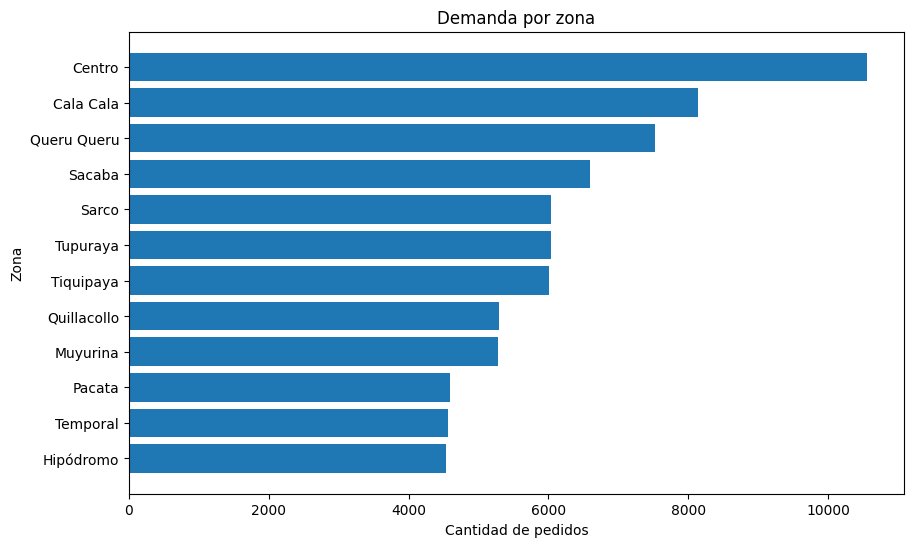

In [11]:
demanda_zonas = con.sql(
    consulta_p1_zonas
).df()

display(demanda_zonas)

plt.figure(figsize=(10, 6))

plt.barh(demanda_zonas["zona_entrega"], demanda_zonas["pedidos"])
plt.gca().invert_yaxis()

plt.title("Demanda por zona")
plt.xlabel("Cantidad de pedidos")
plt.ylabel("Zona")

plt.show()
assert len(demanda_zonas) == 12
assert demanda_zonas["pedidos"].sum() == control.loc[0,"filas"]
assert abs(demanda_zonas["participacion_pct"].sum() - 100) < 0.1

### 2.4 Estimación de riders
$R=\lceil D T/(60U)\rceil$, donde D son entregas promedio por hora de la franja típica, T es la duración promedio válida (min) y U la utilización objetivo. También se calcula el máximo histórico de pedidos como escenario de estrés, no como si fuera la franja promedio. Se informa la cobertura de tiempos válidos para detectar sesgo.

In [12]:
consulta_p1_riders = """
WITH calendario AS (
    SELECT CAST(fecha AS DATE) AS fecha
    FROM generate_series(DATE '2025-01-01', DATE '2025-12-31', INTERVAL 1 DAY) t(fecha)
    WHERE EXTRACT(ISODOW FROM fecha) = ?
), pedidos AS (
    SELECT COUNT(*) AS pedidos,
           COUNT(*) FILTER (WHERE estado = 'entregado') AS entregados,
           COUNT(*) FILTER (WHERE estado = 'entregado' AND tiempo_entrega_min BETWEEN 1 AND 120) AS tiempos_validos,
           SUM(tiempo_entrega_min) FILTER (WHERE estado = 'entregado' AND tiempo_entrega_min BETWEEN 1 AND 120) AS suma_minutos
    FROM plata_pedidos
    WHERE EXTRACT(ISODOW FROM fecha_hora) = ? AND EXTRACT(HOUR FROM fecha_hora) = ?
)
SELECT pedidos, entregados, tiempos_validos,
       (SELECT COUNT(*) FROM calendario) AS ocurrencias,
       entregados * 1.0 / NULLIF((SELECT COUNT(*) FROM calendario),0) AS entregas_promedio_hora,
       suma_minutos / NULLIF(tiempos_validos,0) AS tiempo_promedio,
       100.0 * tiempos_validos / NULLIF(entregados,0) AS cobertura_pct
FROM pedidos
"""
pico_tipico = con.execute(consulta_p1_riders,[dia_pico,dia_pico,hora]).df()
display(pico_tipico)
assert pico_tipico.loc[0,"pedidos"] == hora_pico.iloc[0]["pedidos"]

,pedidos,entregados,tiempos_validos,ocurrencias,entregas_promedio_hora,tiempo_promedio,cobertura_pct
0,1773,1681,1679,52,32.326923,27.38916,99.881023


In [13]:
consulta_p1_maximo_historico = """
SELECT
    DATE_TRUNC('hour', fecha_hora) AS franja,
    COUNT(*) AS pedidos,
    COUNT(*) FILTER (
        WHERE estado = 'entregado'
    ) AS entregados,
    AVG(tiempo_entrega_min) FILTER (
        WHERE estado = 'entregado'
          AND tiempo_entrega_min BETWEEN 1 AND 120
    ) AS tiempo_promedio,
    COUNT(tiempo_entrega_min) FILTER (
        WHERE estado = 'entregado'
          AND tiempo_entrega_min BETWEEN 1 AND 120
    ) AS entregas_con_tiempo_valido
FROM plata_pedidos
GROUP BY franja
ORDER BY pedidos DESC, franja
LIMIT 1
"""
pico_operativo = con.sql(consulta_p1_maximo_historico).df()
display(pico_operativo)

,franja,pedidos,entregados,tiempo_promedio,entregas_con_tiempo_valido
0,2025-02-22 20:00:00,57,56,34.175,56


In [14]:
D = pico_tipico.loc[0,"entregas_promedio_hora"]
T = pico_tipico.loc[0,"tiempo_promedio"]
assert pd.notna(T) and T > 0, "No hay tiempos válidos para estimar riders."
U = 0.80
riders_necesarios = math.ceil(D*T/(60*U))
print("Riders estimados para la franja típica pico:", riders_necesarios)
T_max = pico_operativo.loc[0,"tiempo_promedio"]
if pd.notna(T_max):
    riders_maximo = math.ceil(pico_operativo.loc[0,"entregados"]*T_max/(60*U))
    print("Riders estimados para el máximo histórico:", riders_maximo)
else:
    print("Máximo histórico: sin tiempos válidos para estimar capacidad.")
sensibilidad = pd.DataFrame({"utilizacion": [0.7,0.8,0.9]})
sensibilidad["riders"] = sensibilidad["utilizacion"].map(lambda u: math.ceil(D*T/(60*u)))
display(sensibilidad)

Riders estimados para la franja típica pico: 19
Riders estimados para el máximo histórico: 40


,utilizacion,riders
0,0.7,22
1,0.8,19
2,0.9,17


### 2.5 Número clave y respuesta para Valeria
**Resultados de referencia calculados en pandas; cotejar con las consultas SQL:**

| Indicador | Valor |
|---|---:|
| Franja típica pico | sábado, 13:00–13:59 |
| Pedidos promedio por ocurrencia | 34,10 |
| Pedidos acumulados en esa franja (52 sábados) | 1.773 |
| Zona líder | Centro: 10.559 pedidos (14,04 %) |
| Entregas promedio por ocurrencia | 32,33 |
| Tiempo promedio válido | 27,39 min |
| Cobertura de tiempos válidos | 1.679/1.681 = 99,88 % |
| Riders estimados al 80 % | 19 |
| Máximo histórico de pedidos | 57, sábado 22/02/2025, 20:00 |
| Riders en ese escenario al 80 % | 40 |

**Elementos para la frase gerencial propia:** reforzar la oferta en la franja típica de los sábados a las 13:00; Centro concentra la mayor demanda anual. La capacidad estimada es de 19 riders para la franja a escala de toda la operación, no solo para Centro; el máximo histórico requiere una estimación de 40. Evaluar cobertura por zona antes de asignar turnos.

### 2.6 Abogado del diablo — revisión crítica de los resultados

| Objeción de la IA | Control aplicado / limitación que permanece |
|---|---|
| Un promedio anual puede ocultar la variabilidad y los extremos. | Se añadió la hora de máximo histórico como escenario de estrés (57 pedidos; 40 riders estimados). No es un percentil ni el máximo de carga efectiva. |
| El tiempo desde pedido hasta entrega no equivale a ocupación del rider. | Se explicita el supuesto de una entrega a la vez y el uso de una aproximación. Faltan tiempos de asignación, recogida, retorno y turnos. |
| La utilización de 80 % no está medida. | Sensibilidad: 22, 19 y 17 riders con 70 %, 80 % y 90 % respectivamente. |

**Cierre del integrante:** verificar el SQL, redactar la frase gerencial en palabras propias y confirmar qué objeciones modificaron su conclusión. No presentar la estimación como una necesidad exacta de contratación.

## 3. P5 — ¿Qué restaurantes o riders son un problema y qué haríamos con ellos?
### 3.1 Criterios
- Restaurantes: al menos 100 pedidos, ranking por tasa de cancelación = cancelados / pedidos × 100. Calificación media y cantidad de calificaciones como contexto.
- Riders: al menos 50 entregas con tiempo válido, ranking por tiempo promedio; tasa de cancelación entre pedidos asignados como indicador complementario. Calificaciones de todas las entregas calificadas, independientemente de si el tiempo es válido.
- Umbrales de volumen propuestos (no exigidos por la docente). El tiempo válido se define como 1–120 minutos inclusive, consistente con el esquema de José. Los tiempos fuera del rango se excluyen únicamente del indicador temporal.
- Ordenar por valores sin redondear, presentar redondeados. Desempate por volumen y código. Mostrar top 5.
- Excluir del ranking los códigos que no coinciden con los catálogos; reportar cuántos quedan fuera. No atribuir causalidad a un actor sin controlar zona, clima y preparación. Comparar con el promedio global ponderado correspondiente.

In [15]:
comprobar_tabla("plata_restaurantes", ["cod_rest", "nombre"])
comprobar_tabla("plata_riders", ["rider_id", "nombre"])
for tabla, llave in [("plata_restaurantes", "cod_rest"), ("plata_riders", "rider_id")]:
    filas, unicos = con.execute(f"SELECT COUNT(*), COUNT(DISTINCT {llave}) FROM {tabla}").fetchone()
    assert filas == unicos, f"Llave nula o duplicada en {tabla}; riesgo de multiplicar pedidos."
control_joins = con.sql("""
SELECT COUNT(*) AS pedidos,
       COUNT(*) FILTER (WHERE r.cod_rest IS NULL) AS sin_restaurante_catalogado,
       COUNT(*) FILTER (WHERE d.rider_id IS NULL) AS sin_rider_catalogado
FROM plata_pedidos p
LEFT JOIN plata_restaurantes r ON p.cod_rest = r.cod_rest
LEFT JOIN plata_riders d ON p.rider_id = d.rider_id
""").df()
display(control_joins)
assert control_joins.loc[0,"pedidos"] == control.loc[0,"filas"]

,column_name,column_type,null,key,default,extra
0,cod_rest,VARCHAR,YES,None,None,None
1,nombre,VARCHAR,YES,None,None,None
2,tipo_cocina,VARCHAR,YES,None,None,None
3,zona,VARCHAR,YES,None,None,None
4,comision_pct,BIGINT,YES,None,None,None
5,fecha_alta,TIMESTAMP_NS,YES,None,None,None


,column_name,column_type,null,key,default,extra
0,rider_id,VARCHAR,YES,None,None,None
1,alta,TIMESTAMP_NS,YES,None,None,None
2,zona_base,VARCHAR,YES,None,None,None
3,activo,BOOLEAN,YES,None,None,None
4,nombre,VARCHAR,YES,None,None,None
5,vehiculo,VARCHAR,YES,None,None,None


,pedidos,sin_restaurante_catalogado,sin_rider_catalogado
0,75192,0,300


### 3.2 Ranking de restaurantes

In [16]:
consulta_p5_restaurantes = """
WITH indicadores AS (
    SELECT
        p.cod_rest,
        r.nombre,
        COUNT(*) AS pedidos,
        COUNT(*) FILTER (
            WHERE p.estado = 'cancelado'
        ) AS cancelados,
        (
            100.0 * COUNT(*) FILTER (
                WHERE p.estado = 'cancelado'
            ) / COUNT(*)
        ) AS tasa_cancelacion,
        ROUND(AVG(p.calificacion) FILTER (
            WHERE p.estado = 'entregado'
        ), 2) AS calificacion_promedio,
        COUNT(p.calificacion) FILTER (
            WHERE p.estado = 'entregado'
        ) AS calificaciones
    FROM plata_pedidos p
    INNER JOIN plata_restaurantes r
        ON p.cod_rest = r.cod_rest
    GROUP BY p.cod_rest, r.nombre
    HAVING COUNT(*) >= 100
)
SELECT
    ROW_NUMBER() OVER (
        ORDER BY tasa_cancelacion DESC,
                 pedidos DESC, cod_rest
    ) AS ranking,
    *
FROM indicadores
QUALIFY ranking <= 5
ORDER BY ranking
"""

,ranking,cod_rest,nombre,pedidos,cancelados,tasa_cancelacion,calificacion_promedio,calificaciones
0,1,R017,Burger Kanata Express,2576,386,14.98,3.95,1595
1,2,R016,La Kanata Comida,429,24,5.59,4.12,264
2,3,R028,Don Molle Comida,439,24,5.47,4.17,310
3,4,R025,Sabor Huayllani Pollo,450,24,5.33,4.15,317
4,5,R012,Sabor Cristo Hamburguesas,2174,108,4.97,4.17,1486


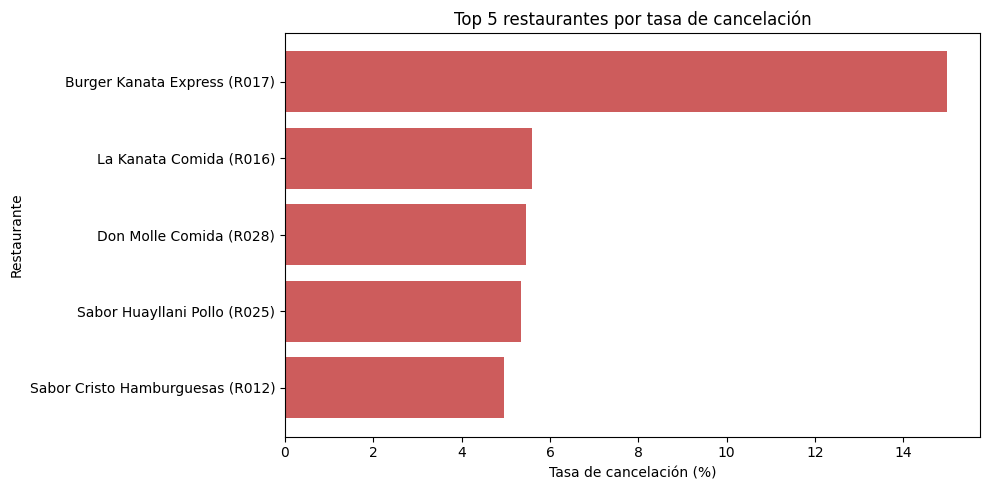

In [17]:
ranking_restaurantes = con.sql(
    consulta_p5_restaurantes
).df()

display(ranking_restaurantes.round(2))

ranking_restaurantes["etiqueta"] = ranking_restaurantes["nombre"] + " (" + ranking_restaurantes["cod_rest"] + ")"

plt.figure(figsize=(10, 5))

plt.barh(ranking_restaurantes["etiqueta"], ranking_restaurantes["tasa_cancelacion"], color="indianred")
plt.gca().invert_yaxis()

plt.title("Top 5 restaurantes por tasa de cancelación")
plt.xlabel("Tasa de cancelación (%)")
plt.ylabel("Restaurante")

plt.tight_layout()
plt.show()

### 3.3 Ranking de riders

In [18]:
consulta_p5_riders = """
WITH indicadores AS (
    SELECT p.rider_id, r.nombre,
           COUNT(*) AS pedidos_asignados,
           COUNT(*) FILTER (WHERE p.estado = 'cancelado') AS cancelados,
           100.0 * COUNT(*) FILTER (WHERE p.estado = 'cancelado') / COUNT(*) AS tasa_cancelacion,
           COUNT(*) FILTER (WHERE p.estado = 'entregado') AS entregas,
           COUNT(*) FILTER (WHERE p.estado = 'entregado' AND p.tiempo_entrega_min BETWEEN 1 AND 120) AS entregas_tiempo_valido,
           AVG(p.tiempo_entrega_min) FILTER (WHERE p.estado = 'entregado' AND p.tiempo_entrega_min BETWEEN 1 AND 120) AS tiempo_promedio,
           AVG(p.calificacion) FILTER (WHERE p.estado = 'entregado') AS calificacion_promedio,
           COUNT(p.calificacion) FILTER (WHERE p.estado = 'entregado') AS calificaciones
    FROM plata_pedidos p
    INNER JOIN plata_riders r ON p.rider_id = r.rider_id
    GROUP BY p.rider_id, r.nombre
    HAVING COUNT(*) FILTER (WHERE p.estado = 'entregado' AND p.tiempo_entrega_min BETWEEN 1 AND 120) >= 50
)
SELECT ROW_NUMBER() OVER (ORDER BY tiempo_promedio DESC, entregas_tiempo_valido DESC, rider_id) AS ranking, *
FROM indicadores
QUALIFY ranking <= 5
ORDER BY ranking
"""

,ranking,rider_id,nombre,pedidos_asignados,cancelados,tasa_cancelacion,entregas,entregas_tiempo_valido,tiempo_promedio,calificacion_promedio,calificaciones
0,1,RD046,Marco Rocha,595,21,3.53,574,572,29.75,3.96,399
1,2,RD078,Luis Rojas,650,32,4.92,618,618,29.61,3.90,442
2,3,RD026,Gabriel Rojas,644,30,4.66,614,614,29.55,3.96,442
3,4,RD074,Luis Mamani,630,28,4.44,602,602,28.82,3.92,443
4,5,RD028,Juan Flores,609,27,4.43,582,581,28.75,4.00,426


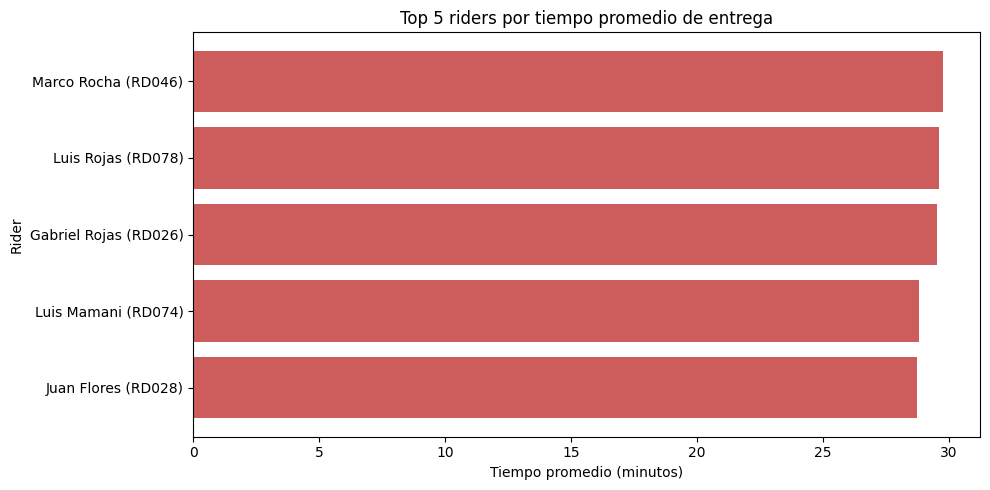

In [19]:
ranking_riders = con.sql(
    consulta_p5_riders
).df()

display(ranking_riders.round(2))

ranking_riders["etiqueta"] = ranking_riders["nombre"] + " (" + ranking_riders["rider_id"] + ")"

plt.figure(figsize=(10, 5))

plt.barh(ranking_riders["etiqueta"], ranking_riders["tiempo_promedio"], color="indianred")
plt.gca().invert_yaxis()

plt.title("Top 5 riders por tiempo promedio de entrega")
plt.xlabel("Tiempo promedio (minutos)")
plt.ylabel("Rider")

plt.tight_layout()
plt.show()

### 3.4 Referencias globales para comparar (universo catalogado, sin mínimo por actor)

In [20]:
referencia_restaurantes = con.sql("""
SELECT 100.0 * COUNT(*) FILTER (WHERE p.estado='cancelado') / NULLIF(COUNT(*),0) AS tasa_cancelacion_global
FROM plata_pedidos p JOIN plata_restaurantes r ON p.cod_rest=r.cod_rest
""").df()
referencia_riders = con.sql("""
SELECT AVG(p.tiempo_entrega_min) FILTER (WHERE p.estado='entregado' AND p.tiempo_entrega_min BETWEEN 1 AND 120) AS tiempo_global
FROM plata_pedidos p JOIN plata_riders r ON p.rider_id=r.rider_id
""").df()
display(referencia_restaurantes.round(2))
display(referencia_riders.round(2))

,tasa_cancelacion_global
0,4.79


,tiempo_global
0,25.1


### 3.5 Número clave y respuesta para Valeria
**Resultados de referencia calculados en pandas; cotejar con las consultas SQL:**

| Indicador | Valor |
|---|---:|
| Restaurante prioritario | R017 — Burger Kanata Express |
| Pedidos / cancelaciones | 2.576 / 386 |
| Tasa de cancelación | 14,98 % |
| Tasa general de restaurantes catalogados | 4,79 % |
| Razón frente a la tasa general | 3,13 veces |
| Rider prioritario | RD046 — Marco Rocha |
| Entregas / entregas con tiempo válido | 574 / 572 |
| Tiempo medio de entrega | 29,75 min |
| Tiempo medio de entregas con rider catalogado | 25,10 min |
| Brecha frente a la referencia | +4,65 min |
| Pedidos sin rider catalogado | 300 |

**Elementos para la frase gerencial propia:** priorizar el diagnóstico de las cancelaciones de R017; revisar rutas, zonas, distancias y preparación en las entregas de RD046. Los rankings identifican casos para investigar, no prueban culpabilidad ni justifican sanciones.

### 3.6 Abogado del diablo — revisión crítica de los resultados

| Objeción de la IA | Control aplicado / limitación que permanece |
|---|---|
| Las cancelaciones podrían deberse al cliente, la plataforma o a falta de riders. | Se muestran volumen y tasa global de referencia; se recomienda investigar causas, no atribuir responsabilidad al restaurante. Faltan motivos de cancelación. |
| La duración incluye preparación y puede variar por zona, distancia y clima. | Se consideran estos factores como variables de confusión; antes de evaluar a un rider debe compararse en condiciones semejantes. No se ha estimado un efecto causal. |
| El ranking excluye pedidos sin rider y las calificaciones no son universales. | El control de JOIN cuantifica los 300 sin rider catalogado, se informa el tamaño muestral y se filtran tiempos y calificaciones por separado. |

**Cierre del integrante:** cotejar los resultados, escribir su frase final y dejar constancia de cómo las objeciones modificaron la recomendación.

### 4. Cotejo SQL contra la verificación independiente
Ejecutar antes de cerrar la conexión. Los resultados esperados corresponden a las decisiones actuales de limpieza y no sustituyen los controles de la base definitiva.

In [21]:
assert (dia_pico, hora) == (6, 13)
assert abs(hora_pico.iloc[0]["pedidos_promedio"] - 34.0961538462) < 0.001
assert demanda_zonas.iloc[0]["zona_entrega"] == "Centro"
assert demanda_zonas.iloc[0]["pedidos"] == 10559
assert riders_necesarios == 19 and riders_maximo == 40
assert ranking_restaurantes.iloc[0]["cod_rest"] == "R017"
assert abs(ranking_restaurantes.iloc[0]["tasa_cancelacion"] - 14.98447205) < 0.001
assert ranking_riders.iloc[0]["rider_id"] == "RD046"
assert abs(ranking_riders.iloc[0]["tiempo_promedio"] - 29.74912587) < 0.001
assert control_joins.loc[0,"sin_rider_catalogado"] == 300
assert abs(referencia_restaurantes.loc[0,"tasa_cancelacion_global"] - 4.79040323) < 0.001
assert abs(referencia_riders.loc[0,"tiempo_global"] - 25.1038288) < 0.001
print("P1 y P5: consultas SQL coinciden con la verificación independiente.")

P1 y P5: consultas SQL coinciden con la verificación independiente.


In [22]:
con.close()

## Anexo — Verificación independiente y evidencia de IA
Esta celda se ejecutó en el entorno de revisión con los archivos originales y `plata.py` de José, sin usar DuckDB. Los resultados y cuatro gráficos guardados son reales y constituyen una comprobación independiente, no salidas de las consultas SQL anteriores. También incluye las dos evidencias de «Atrapé a la IA». Al fusionar el notebook con los de José y Suri, puede conservarse el anexo o trasladarse su evidencia al README. El estudiante debe contrastar las salidas SQL y validar sus interpretaciones antes de entregar.

/content/plata.py:74: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  rechazos = pd.concat([descartadas, huerfanos], ignore_index=True).astype(str)


Bronce: 76232 | Plata: 75192 | Rechazos: 1040 | Monto plata: Bs 4,413,314.04
P1. Franja pico (día ISO, hora, pedidos, promedio): {'dia': 6.0, 'hora': 13.0, 'pedidos': 1773.0, 'promedio': 34.09615384615385}
Entregas promedio: 32.3269; tiempo: 27.3892; cobertura: 99.88%; riders al 80%: 19
Sensibilidad 70/80/90%: [22, 19, 17]
Máximo histórico: 2025-02-22 20:00:00, 57 pedidos, 56 entregados, 40 riders


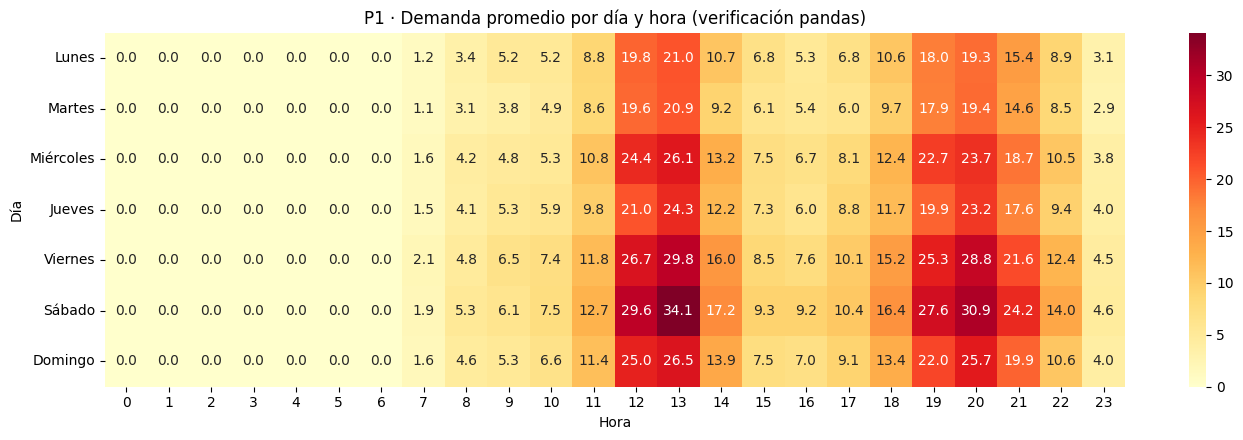

zona_entrega  pedidos  participacion_pct
      Centro    10559              14.04
   Cala Cala     8147              10.83
 Queru Queru     7524              10.01
      Sacaba     6603               8.78
       Sarco     6043               8.04
    Tupuraya     6034               8.02
   Tiquipaya     6009               7.99
 Quillacollo     5298               7.05
    Muyurina     5281               7.02
      Pacata     4588               6.10
    Temporal     4567               6.07
   Hipódromo     4539               6.04


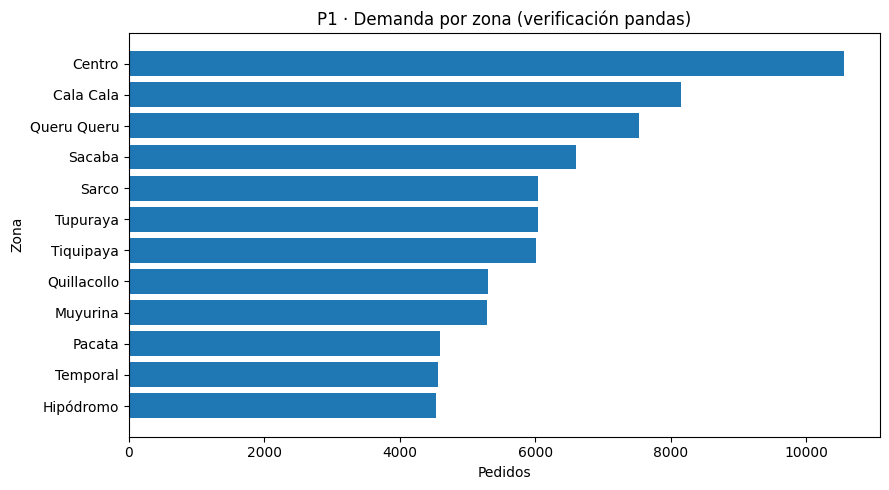

P5. Tasa global: 4.7904% | sin restaurante catalogado: 0
cod_rest                    nombre  pedidos  cancelados  calificacion  calificaciones  tasa_cancelacion
    R017     Burger Kanata Express     2576         386          3.95            1595             14.98
    R016          La Kanata Comida      429          24          4.12             264              5.59
    R028          Don Molle Comida      439          24          4.17             310              5.47
    R025     Sabor Huayllani Pollo      450          24          4.15             317              5.33
    R012 Sabor Cristo Hamburguesas     2174         108          4.17            1486              4.97


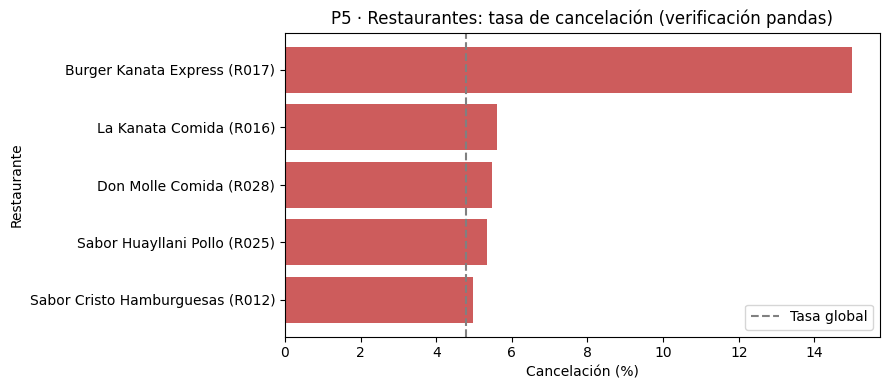

Tiempo global: 25.1038 min | sin rider catalogado: 300
rider_id        nombre  pedidos_asignados  cancelados  entregas  entregas_tiempo_valido  tiempo_promedio  calificacion  calificaciones  tasa_cancelacion
   RD046   Marco Rocha                595          21       574                     572            29.75          3.96             399              3.53
   RD078    Luis Rojas                650          32       618                     618            29.61          3.90             442              4.92
   RD026 Gabriel Rojas                644          30       614                     614            29.55          3.96             442              4.66
   RD074   Luis Mamani                630          28       602                     602            28.82          3.92             443              4.44
   RD028   Juan Flores                609          27       582                     581            28.75          4.00             426              4.43


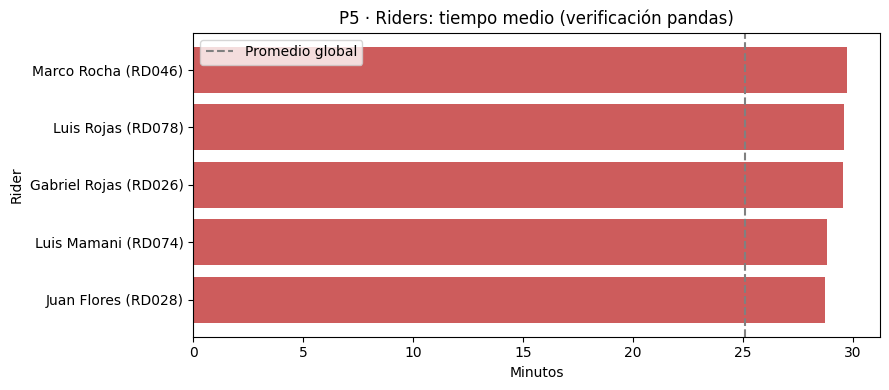

Caso 1: 30 fechas; día 5: 241 pedidos, máxima 5.0; primer máximo >5: 2025-09-15
Caso 2: 4554 calificaciones no nulas antes; 4442 después del filtro de tiempos; 112 excluidas.


In [24]:
# Comprobación independiente: ZIP original + función de limpieza de José.
# Esta celda es opcional para quien tenga la base definitiva; no sustituye el SQL.
from pathlib import Path
import zipfile, json, importlib.util, math
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

zip_path = Path("YaLlego_datos.zip")
plata_path = next((p for p in [Path("plata.py"), Path("plata (1).py")] if p.is_file()), None)
if not zip_path.is_file() or plata_path is None:
    print("Comprobación opcional omitida: se necesitan el ZIP original y plata.py.")
else:
    with zipfile.ZipFile(zip_path) as z:
        frames = []
        for f in sorted(z.namelist()):
            if "/pedidos/" not in f or not f.endswith((".csv", ".json")):
                continue
            d = (pd.read_csv(z.open(f), dtype=str, keep_default_na=False, na_values=[""])
                 if f.endswith(".csv") else pd.DataFrame(json.load(z.open(f)), dtype="string"))
            d["archivo_origen"] = Path(f).name
            frames.append(d)
        b = pd.concat(frames, ignore_index=True).astype("string")
        rest = pd.read_excel(z.open("YaLlego/restaurantes.xlsx"), header=2)
        zones = pd.read_csv(z.open("YaLlego/zonas.csv"))
        riders_cat = pd.json_normalize(json.load(z.open("YaLlego/riders_api.json"))["data"]).rename(columns={"id":"rider_id", "perfil.nombre":"nombre"})
        sep = pd.read_csv(z.open("YaLlego/raw/pedidos/pedidos_2025_09.csv"))
        ago = pd.read_csv(z.open("YaLlego/raw/pedidos/pedidos_2025_08.csv"))
    spec = importlib.util.spec_from_file_location("plata_verificacion", plata_path)
    modulo = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(modulo)
    p, rech = modulo.limpiar(b, zones.zona.tolist(), rest)
    assert len(b) == 76232 and len(p) == 75192 and len(rech) == 1040
    assert p.pedido_id.is_unique and p.fecha_hora.notna().all()
    assert rest.cod_rest.is_unique and riders_cat.rider_id.is_unique
    print(f"Bronce: {len(b)} | Plata: {len(p)} | Rechazos: {len(rech)} | Monto plata: Bs {p.monto_bs.sum():,.2f}")
    # P1: grilla completa y denominadores por día de semana.
    p = p.assign(dia=p.fecha_hora.dt.dayofweek+1, hora=p.fecha_hora.dt.hour)
    dias = pd.date_range("2025-01-01", "2025-12-31").dayofweek.value_counts()
    h = p.groupby(["dia", "hora"]).size().reindex(pd.MultiIndex.from_product([range(1,8),range(24)],names=["dia","hora"]), fill_value=0).rename("pedidos").reset_index()
    h["promedio"] = h.pedidos / h.dia.map(lambda d: dias[d-1])
    pico = h.sort_values(["promedio","dia","hora"], ascending=[False,True,True]).iloc[0]
    q = p[(p.dia == pico.dia) & (p.hora == pico.hora) & p.estado.eq("entregado")]
    tv = q.tiempo_entrega_min.where(q.tiempo_entrega_min.between(1,120))
    D, T = len(q)/dias[int(pico.dia)-1], tv.mean()
    print("P1. Franja pico (día ISO, hora, pedidos, promedio):", pico.to_dict())
    print(f"Entregas promedio: {D:.4f}; tiempo: {T:.4f}; cobertura: {100*tv.count()/len(q):.2f}%; riders al 80%: {math.ceil(D*T/48)}")
    print("Sensibilidad 70/80/90%:", [math.ceil(D*T/(60*u)) for u in [.7,.8,.9]])
    p["franja"] = p.fecha_hora.dt.floor("h")
    maxh = p.groupby("franja").size().rename("pedidos").reset_index().sort_values(["pedidos","franja"],ascending=[False,True]).iloc[0]
    e = p[(p.franja == maxh.franja) & p.estado.eq("entregado")]
    print(f"Máximo histórico: {maxh.franja}, {maxh.pedidos} pedidos, {len(e)} entregados, {math.ceil(len(e)*e.tiempo_entrega_min.where(e.tiempo_entrega_min.between(1,120)).mean()/48)} riders")
    hz = h.pivot(index="dia",columns="hora",values="promedio")
    hz.index = ["Lunes","Martes","Miércoles","Jueves","Viernes","Sábado","Domingo"]
    plt.figure(figsize=(14,4.5)); sns.heatmap(hz,cmap="YlOrRd",annot=True,fmt=".1f"); plt.title("P1 · Demanda promedio por día y hora (verificación pandas)"); plt.xlabel("Hora"); plt.ylabel("Día"); plt.tight_layout(); plt.show()
    zrank = p.zona_entrega.value_counts().rename("pedidos").reset_index()
    zrank["participacion_pct"] = zrank.pedidos / len(p)*100
    print(zrank.round(2).to_string(index=False))
    plt.figure(figsize=(9,5)); plt.barh(zrank.zona_entrega, zrank.pedidos); plt.gca().invert_yaxis(); plt.title("P1 · Demanda por zona (verificación pandas)"); plt.xlabel("Pedidos"); plt.ylabel("Zona"); plt.tight_layout(); plt.show()
    # P5: mismos filtros, agregados y desempates que SQL.
    p["cancelado"] = p.estado.eq("cancelado"); p["entregado"] = p.estado.eq("entregado")
    p["valid"] = p.entregado & p.tiempo_entrega_min.between(1,120)
    p["t"] = p.tiempo_entrega_min.where(p.valid); p["c"] = p.calificacion.where(p.entregado)
    a = p.merge(rest[["cod_rest","nombre"]],on="cod_rest",validate="many_to_one")
    rr = a.groupby(["cod_rest","nombre"]).agg(pedidos=("pedido_id","size"),cancelados=("cancelado","sum"),calificacion=("c","mean"),calificaciones=("c","count")).reset_index()
    rr["tasa_cancelacion"] = rr.cancelados/rr.pedidos*100
    rr = rr[rr.pedidos>=100].sort_values(["tasa_cancelacion","pedidos","cod_rest"],ascending=[False,False,True]).head(5).copy()
    print(f"P5. Tasa global: {a.cancelado.mean()*100:.4f}% | sin restaurante catalogado: {len(p)-len(a)}")
    print(rr.round(2).to_string(index=False))
    rr["etiqueta"] = rr.nombre+" ("+rr.cod_rest+")"
    plt.figure(figsize=(9,4)); plt.barh(rr.etiqueta,rr.tasa_cancelacion,color="indianred"); plt.gca().invert_yaxis(); plt.axvline(a.cancelado.mean()*100,ls="--",color="gray",label="Tasa global"); plt.legend(); plt.title("P5 · Restaurantes: tasa de cancelación (verificación pandas)"); plt.xlabel("Cancelación (%)"); plt.ylabel("Restaurante"); plt.tight_layout(); plt.show()
    a = p.merge(riders_cat[["rider_id","nombre"]],on="rider_id",validate="many_to_one")
    dr = a.groupby(["rider_id","nombre"]).agg(pedidos_asignados=("pedido_id","size"),cancelados=("cancelado","sum"),entregas=("entregado","sum"),entregas_tiempo_valido=("valid","sum"),tiempo_promedio=("t","mean"),calificacion=("c","mean"),calificaciones=("c","count")).reset_index()
    dr["tasa_cancelacion"] = dr.cancelados/dr.pedidos_asignados*100
    dr = dr[dr.entregas_tiempo_valido>=50].sort_values(["tiempo_promedio","entregas_tiempo_valido","rider_id"],ascending=[False,False,True]).head(5).copy()
    print(f"Tiempo global: {a.t.mean():.4f} min | sin rider catalogado: {len(p)-len(a)}")
    print(dr.round(2).to_string(index=False))
    dr["etiqueta"] = dr.nombre+" ("+dr.rider_id+")"
    plt.figure(figsize=(9,4)); plt.barh(dr.etiqueta,dr.tiempo_promedio,color="indianred"); plt.gca().invert_yaxis(); plt.axvline(a.t.mean(),ls="--",color="gray",label="Promedio global"); plt.legend(); plt.title("P5 · Riders: tiempo medio (verificación pandas)"); plt.xlabel("Minutos"); plt.ylabel("Rider"); plt.tight_layout(); plt.show()
    # Evidencias reales de Atrapé a la IA, sobre archivos originales.
    sep["fecha"] = pd.to_datetime(sep.fecha_hora).dt.normalize()
    mx = sep.groupby("fecha").calificacion.max()
    dia5 = sep[sep.fecha == pd.Timestamp("2025-09-05")]
    print(f"Caso 1: {len(mx)} fechas; día 5: {len(dia5)} pedidos, máxima {dia5.calificacion.max()}; primer máximo >5: {mx[mx>5].index.min().date()}")
    assert len(mx)==30 and len(dia5)==241
    base = ago.estado.eq("entregado") & ago.rider_id.isin(riders_cat.rider_id)
    tv = ago.tiempo_entrega_min.gt(0) & ago.tiempo_entrega_min.lt(999)
    c1,c2=ago.loc[base,"calificacion"].count(),ago.loc[base&tv,"calificacion"].count()
    print(f"Caso 2: {c1} calificaciones no nulas antes; {c2} después del filtro de tiempos; {c1-c2} excluidas.")
    assert (c1,c2)==(4554,4442)
